# Reasoning behavior

Base → SFT → Refined → Think. Base BBH is not reported.

### Run the notebook without syncing all dependencies:

```bash
uv sync --only-group notebooks
```

In [19]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from utils.config import BENCHMARKS, COLORS, MODELS, PRIMARY_METRICS, STAGES, TITLES

from utils import data, style

ROOT = Path.cwd().parent
RESULTS = ROOT / "results"
FIGURES = Path("figures")
style.set_style()

In [20]:
def last_box(text):
    matches = list(re.finditer(r"\\(?:boxed|fbox)\s*\{", text))
    if matches:
        start, depth = matches[-1].end(), 1
        for i in range(start, len(text)):
            depth += (text[i] == "{") - (text[i] == "}")
            if depth == 0:
                return text[start:i].strip()
    return ""


def repeated_spans(text):
    words = text.lower().split()
    spans = list(zip(*(words[i:] for i in range(10))))
    return 1 - len(set(spans)) / len(spans) if spans else 0.0

In [21]:
runs, metrics = data.load_metrics(RESULTS)
rows, question_rows, cap_rows = [], [], []
for (stage, benchmark), run in runs.items():
    directory = RESULTS / MODELS[stage] / benchmark
    parts = run["tasks"][1:] if benchmark == "bbh" else run["tasks"]
    paths = sorted(directory.glob("task-*-predictions.jsonl"))
    assert len(paths) == len(parts)
    parts = {part["alias"].split(":")[0]: part for part in parts}
    for path in paths:
        name = path.name.split("-", 2)[2].removesuffix("-predictions.jsonl")
        meta = json.loads(
            path.with_name(
                path.name.replace("-predictions.jsonl", "-metrics.json")
            ).read_text()
        )
        cfg, model = meta["task_config"], meta["model_config"]
        gen = cfg["generation_kwargs"]
        assert meta["compute_config"]["batch_size"] == "auto"
        assert gen["truncate_context"] is False
        records = [json.loads(line) for line in path.open()]
        assert len(records) == parts[name]["num_instances"]
        assert len({r["doc_id"] for r in records}) == len(records)
        max_prompt = max(
            o["context_tokens"] for r in records for o in r["model_output"]
        )
        cap = min(gen["max_gen_toks"], model["max_length"] - max_prompt)
        cap_rows.append(
            {
                "stage": stage,
                "benchmark": benchmark,
                "task": name,
                "requested": gen["max_gen_toks"],
                "model_limit": model["max_length"],
                "max_prompt": max_prompt,
                "cap": cap,
                "problems": len(records),
            }
        )
        for record in records:
            outputs = record["model_output"]
            assert len(outputs) == gen.get("repeats", 1)
            corrects = []
            for sample, output in enumerate(outputs):
                text = output.get("original_output", output["continuation"])
                closed = "</think>" in text
                reasoning = output.get(
                    "reasoning_content",
                    text.rsplit("</think>", 1)[0] if closed else None,
                )
                final = text.rsplit("</think>", 1)[1] if closed else None
                count = output["num_tokens"]
                assert 0 < count <= cap, (stage, benchmark, name, count, cap)
                if benchmark.startswith("aime"):
                    correct = np.nan
                    answered = bool(last_box(text))
                else:
                    metric = (
                        "exact_match"
                        if benchmark == "bbh"
                        else PRIMARY_METRICS[benchmark]
                    )
                    correct = bool(record["metrics"][metric])
                    if benchmark == "math500":
                        answered = bool(last_box(text))
                    elif benchmark == "gpqa":
                        answered = output["answer_format_correct"] == 1
                    elif benchmark == "bbh":
                        answered = bool(output["model_answer"].strip())
                    else:
                        answered = bool(output["continuation"].strip())
                corrects.append(correct)
                rows.append(
                    {
                        "stage": stage,
                        "benchmark": benchmark,
                        "task": name,
                        "problem": record["native_id"],
                        "sample": sample,
                        "tokens": count,
                        "context": output["context_tokens"],
                        "cap": cap,
                        "at_cap": count == cap,
                        "closed_think": closed,
                        "final_section": bool(final and final.strip()),
                        "answered": answered,
                        "boxed": bool(last_box(text))
                        if benchmark in ["math500", "aime-2024", "aime-2025"]
                        else np.nan,
                        "final_box": bool(last_box(final or ""))
                        if benchmark in ["math500", "aime-2024", "aime-2025"]
                        else np.nan,
                        "correct": correct,
                        "repeated": repeated_spans(text),
                        "reasoning_words": len(reasoning.split())
                        if reasoning is not None
                        else np.nan,
                        "final_words": len(final.split())
                        if final is not None
                        else np.nan,
                        "finish_reason": output.get("finish_reason"),
                        "stop_reason": output.get("stop_reason"),
                        "reported_cap": record["metrics"].get(
                            "max_tokens_reached", np.nan
                        ),
                    }
                )
            question_rows.append(
                {
                    "stage": stage,
                    "benchmark": benchmark,
                    "task": name,
                    "problem": record["native_id"],
                    "tokens": np.mean([o["num_tokens"] for o in outputs]),
                    "score": record["metrics"]["pass_at_1"]
                    if benchmark.startswith("aime")
                    else float(corrects[0]),
                }
            )

In [22]:
df = pd.DataFrame(rows)
questions = pd.DataFrame(question_rows)
caps = pd.DataFrame(cap_rows)
order = pd.MultiIndex.from_tuples(
    [(b, s) for b in BENCHMARKS for s in STAGES if (s, b) in runs],
    names=["benchmark", "stage"],
)
summary = (
    df.groupby(["benchmark", "stage"], sort=False)
    .agg(
        responses=("tokens", "size"),
        mean_tokens=("tokens", "mean"),
        median_tokens=("tokens", "median"),
        p10=("tokens", lambda x: x.quantile(0.1)),
        p90=("tokens", lambda x: x.quantile(0.9)),
        p95=("tokens", lambda x: x.quantile(0.95)),
        p99=("tokens", lambda x: x.quantile(0.99)),
        at_cap=("at_cap", "mean"),
        closed_think=("closed_think", "mean"),
        final_section=("final_section", "mean"),
        answered=("answered", "mean"),
        repetition=("repeated", "mean"),
    )
    .reindex(order)
)
summary["accuracy"] = questions.groupby(["benchmark", "stage"]).score.mean()
for (benchmark, stage), values in summary.iterrows():
    t = runs[stage, benchmark]["tasks"][0]
    assert values.responses == t["num_instances"] * t["task_config"].get(
        "generation_kwargs", {}
    ).get("repeats", 1)
    assert np.isclose(values.accuracy, t["metrics"]["primary_score"])
    extra = t["metrics"].get("extra_metrics", {})
    key = "num_tokens_micro" if benchmark == "bbh" else "num_tokens"
    if key in extra:
        assert np.isclose(values.mean_tokens, extra[key], rtol=1e-12)
assert not df.duplicated(["stage", "benchmark", "task", "problem", "sample"]).any()

assert caps.groupby(["benchmark", "task"]).cap.nunique().eq(1).all()
for benchmark in BENCHMARKS:
    groups = questions[questions.benchmark == benchmark].groupby("stage")
    keys = [set(zip(g.task, g.problem)) for _, g in groups]
    assert all(key == keys[0] for key in keys)
print(
    f"{len(df):,} responses, {len(questions):,} question evaluations, {len(runs)} complete stage/suite runs."
)

33,169 responses, 25,729 question evaluations, 23 complete stage/suite runs.


## Length distributions

All responses, including cap hits. Dotted lines mark token caps.

responses  mean_tokens  median_tokens     p10  \
benchmark stage                                                         
gpqa      Base                448      12070.0         4096.0   706.0   
          SFT                 448      19697.0        29821.0  1647.0   
          Refined             448       8685.0         8274.0  1295.0   
          Think (RLVR)        448       7157.0         6300.0  1004.0   
math500   Base                500       2176.0         1788.0   421.0   
          SFT                 500       6375.0         3474.0  1205.0   
          Refined             500       5382.0         3194.0  1148.0   
          Think (RLVR)        500       4512.0         2574.0  1051.0   
aime-2024 Base                960       4243.0         4002.0  3478.0   
          SFT                 960      13845.0        16384.0  6610.0   
          Refined             960      13158.0        15938.0  6676.0   
          Think (RLVR)        960      11942.0        13274.0  4967.0   
aime-2025 Base                960       4150.0         4000.0  3346.0   
          SFT                 960      13611.0        16384.0  5439.0   
          Refined             960      13470.0        16384.0  5499.0   
          Think (RLVR)        960      12328.0        14069.0  4367.0   
bbh       SFT                6511       7133.0         1835.0   669.0   
          Refined            6511       3036.0         1770.0   658.0   
          Think (RLVR)       6511       2376.0         1384.0   613.0   
ifeval    Base                541       9188.0         1463.0   286.0   
          SFT                 541       7260.0         1158.0   500.0   
          Refined             541       3275.0         1162.0   481.0   
          Think (RLVR)        541       1838.0          941.0   442.0   

                            p90      p95      p99  
benchmark stage                                    
gpqa      Base          29821.0  29821.0  29821.0  
          SFT           29821.0  29821.0  29821.0  
          Refined       15067.0  18962.0  29821.0  
          Think (RLVR)  13957.0  16107.0  29821.0  
math500   Base           4086.0   4103.0   4277.0  
          SFT           15143.0  22749.0  31942.0  
          Refined       11682.0  16277.0  29173.0  
          Think (RLVR)  10656.0  14803.0  22782.0  
aime-2024 Base           4107.0   4370.0  16384.0  
          SFT           16384.0  16384.0  16384.0  
          Refined       16384.0  16384.0  16384.0  
          Think (RLVR)  16384.0  16384.0  16384.0  
aime-2025 Base           4107.0   4328.0  16384.0  
          SFT           16384.0  16384.0  16384.0  
          Refined       16384.0  16384.0  16384.0  
          Think (RLVR)  16384.0  16384.0  16384.0  
bbh       SFT           32520.0  32579.0  32635.0  
          Refined        5977.0   8992.0  32575.0  
          Think (RLVR)   4415.0   6475.0  32530.0  
ifeval    Base          32352.0  32352.0  32352.0  
          SFT           32352.0  32352.0  32352.0  
          Refined        4984.0  32352.0  32352.0  
          Think (RLVR)   2767.0   4016.0  32352.0

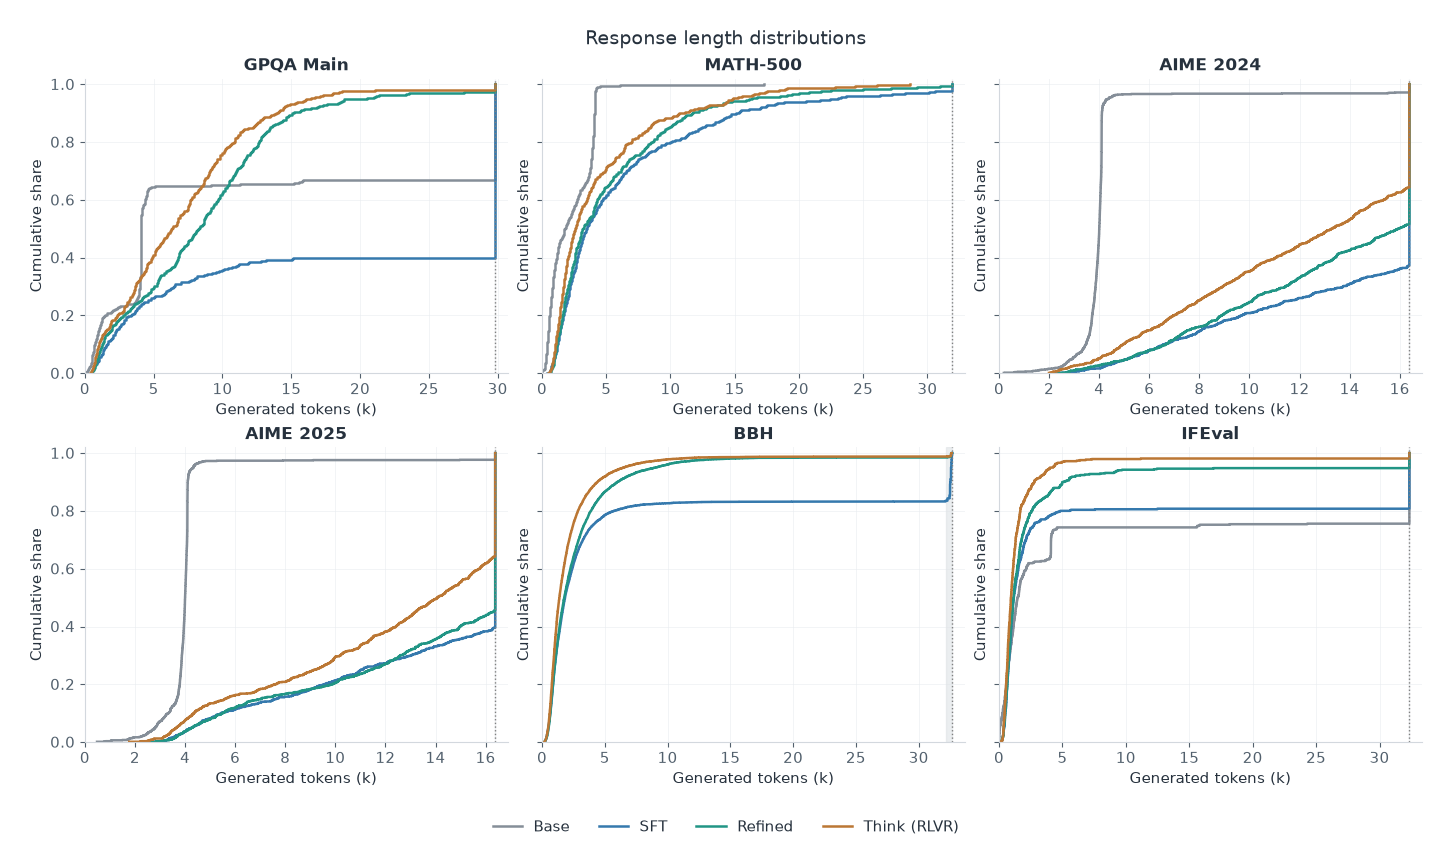

In [23]:
display(
    summary[
        ["responses", "mean_tokens", "median_tokens", "p10", "p90", "p95", "p99"]
    ].round(0)
)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True, layout="constrained")
for ax, benchmark in zip(axes.flat, BENCHMARKS):
    for stage in STAGES:
        values = np.sort(
            df.loc[(df.benchmark == benchmark) & (df.stage == stage), "tokens"]
        )
        if len(values):
            ax.step(
                values / 1000,
                np.arange(1, len(values) + 1) / len(values),
                where="post",
                color=COLORS[stage],
                label=stage,
                lw=1.8,
            )
    limits = caps.loc[caps.benchmark == benchmark, "cap"] / 1000
    ax.axvspan(limits.min(), limits.max(), color="#dfe3e6", alpha=0.6)
    ax.axvline(limits.max(), color="gray", ls=":", lw=1)
    ax.set(
        title=TITLES[benchmark],
        xlabel="Generated tokens (k)",
        ylabel="Cumulative share",
        xlim=(0, limits.max() * 1.03),
        ylim=(0, 1.02),
    )
    ax.grid(alpha=0.6)
fig.legend(
    *axes.flat[0].get_legend_handles_labels(),
    loc="outside lower center",
    ncol=4,
    frameon=False,
)
fig.suptitle(
    "Response length distributions",
    fontsize=14,
)
style.save(fig, FIGURES / "behavior_01_length_distributions")

## Reasoning and final sections

Word counts from responses with `</think>`. Missing markers are excluded.

In [24]:
segments = (
    df[df.closed_think]
    .groupby(["benchmark", "stage"])
    .agg(
        marked_responses=("tokens", "size"),
        reasoning_mean_words=("reasoning_words", "mean"),
        reasoning_median_words=("reasoning_words", "median"),
        reasoning_p90_words=("reasoning_words", lambda x: x.quantile(0.9)),
        final_median_words=("final_words", "median"),
    )
    .reindex(order)
)
segments.insert(0, "Closing marker (%)", 100 * summary.closed_think)
display(segments.round(1))

Closing marker (%)  marked_responses  \
benchmark stage                                                
gpqa      Base                        11.4                51   
          SFT                         40.0               179   
          Refined                     97.3               436   
          Think (RLVR)                98.0               439   
math500   Base                        54.0               270   
          SFT                         97.8               489   
          Refined                     99.8               499   
          Think (RLVR)                99.8               499   
aime-2024 Base                         7.5                72   
          SFT                         38.0               365   
          Refined                     54.0               518   
          Think (RLVR)                66.7               640   
aime-2025 Base                        10.1                97   
          SFT                         41.2               396   
          Refined                     48.9               469   
          Think (RLVR)                67.8               651   
bbh       SFT                         83.3              5423   
          Refined                     98.6              6419   
          Think (RLVR)                98.9              6442   
ifeval    Base                        44.4               240   
          SFT                         83.5               452   
          Refined                     95.7               518   
          Think (RLVR)                98.5               533   

                        reasoning_mean_words  reasoning_median_words  \
benchmark stage                                                        
gpqa      Base                         629.8                   577.0   
          SFT                         2642.0                  1946.0   
          Refined                     4682.6                  4754.0   
          Think (RLVR)                3832.6                  3698.0   
math500   Base                         650.5                   474.5   
          SFT                         3048.7                  1724.0   
          Refined                     2803.9                  1729.0   
          Think (RLVR)                2346.0                  1308.0   
aime-2024 Base                        1275.2                  1241.0   
          SFT                         5178.1                  4838.0   
          Refined                     5555.8                  5577.0   
          Think (RLVR)                5476.5                  5228.5   
aime-2025 Base                        1372.0                  1357.0   
          SFT                         5108.9                  4988.0   
          Refined                     5741.1                  5942.0   
          Think (RLVR)                6002.3                  5989.0   
bbh       SFT                         1225.8                   881.0   
          Refined                     1611.2                  1041.0   
          Think (RLVR)                1226.5                   789.0   
ifeval    Base                        1405.6                   340.5   
          SFT                          657.7                   462.5   
          Refined                      874.6                   498.5   
          Think (RLVR)                 612.8                   393.0   

                        reasoning_p90_words  final_median_words  
benchmark stage                                                  
gpqa      Base                       1019.0               149.0  
          SFT                        6118.8               144.0  
          Refined                    8094.5               184.0  
          Think (RLVR)               7038.2               181.0  
math500   Base                       1393.2               130.5  
          SFT                        7645.4               209.0  
          Refined                    6415.6               206.0  
          Think (RLVR)      

## The base model loves 4k tokens

First 8k tokens. Percentages use all Base responses.

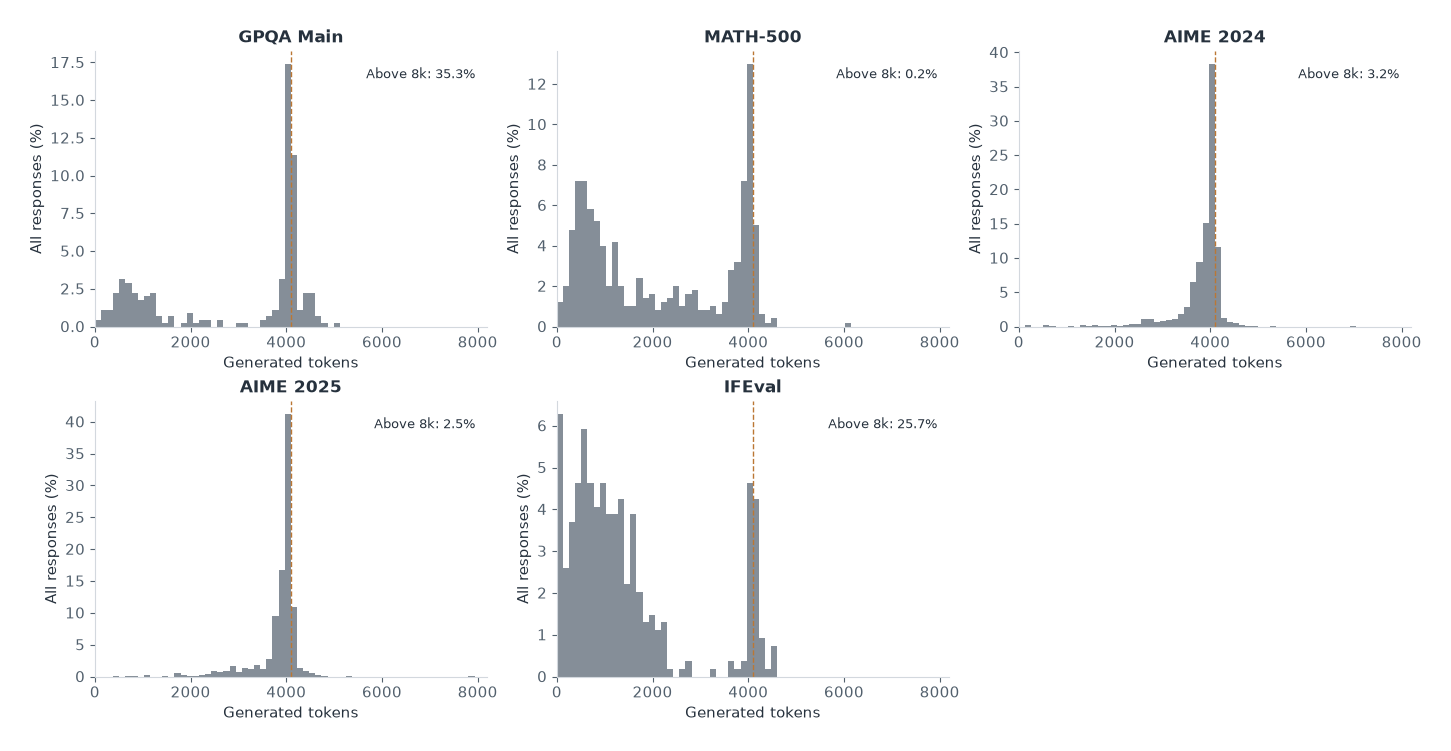

,N,Cap,At 4096 (%),Above 4096 (%),3840–4352 (%),Closing marker | near 4k (%),Answer signal | near 4k (%)
benchmark,,,,,,,
GPQA Main,448,29821,5.1,48.2,33.0,0.7,7.4
MATH-500,500,31942,0.8,5.8,25.8,9.3,26.4
AIME 2024,960,16384,3.3,14.6,66.2,2.0,6.6
AIME 2025,960,16384,2.1,14.7,70.2,1.8,5.9
IFEval,541,32352,1.1,30.7,10.2,0.0,100.0


In [25]:
base = df[df.stage == "Base"]
cliff_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout="constrained")
base_benchmarks = [b for b in BENCHMARKS if b != "bbh"]
for ax, benchmark in zip(axes.flat, base_benchmarks):
    g = base[base.benchmark == benchmark]
    near = g[g.tokens.between(3840, 4352)]
    ax.hist(
        g.tokens,
        bins=np.arange(0, 8193, 128),
        weights=np.full(len(g), 100 / len(g)),
        color=COLORS["Base"],
    )
    ax.axvline(4096, color="#BB7734", ls="--", lw=1)
    ax.text(
        0.97,
        0.94,
        f"Above 8k: {100 * g.tokens.gt(8192).mean():.1f}%",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
    )
    ax.set(
        title=TITLES[benchmark],
        xlabel="Generated tokens",
        ylabel="All responses (%)",
        xlim=(0, 8192),
    )
    cliff_rows.append(
        {
            "benchmark": TITLES[benchmark],
            "N": len(g),
            "Cap": g.cap.min(),
            "At 4096 (%)": 100 * g.tokens.eq(4096).mean(),
            "Above 4096 (%)": 100 * g.tokens.gt(4096).mean(),
            "3840–4352 (%)": 100 * len(near) / len(g),
            "Closing marker | near 4k (%)": 100 * near.closed_think.mean(),
            "Answer signal | near 4k (%)": 100 * near.answered.mean(),
        }
    )
axes.flat[-1].axis("off")
style.save(fig, FIGURES / "behavior_04_base_4k")
display(pd.DataFrame(cliff_rows).set_index("benchmark").round(1))

## Caps and completion

Cap = `min(requested tokens, model limit − longest prompt)` per task.
A cap hit does not prove truncation and stopping below it does not prove completion. Finish reasons are not saved.

GPQA's saved cap flag uses the requested budget and misses runtime cap hits.

Especially repetition SFT and RLVR seem to improve completion behavior,

,requested,model_limit,cap_min,cap_max
benchmark,,,,
GPQA Main,131072,32768,29821,29821
MATH-500,32768,32768,31942,31942
AIME 2024,16384,32768,16384,16384
AIME 2025,16384,32768,16384,16384
BBH,32768,32768,32145,32682
IFEval,32768,32768,32352,32352


At cap (%)  Closing marker (%)  \
benchmark stage                                          
gpqa      Base                33.0                11.4   
          SFT                 60.0                40.0   
          Refined              2.7                97.3   
          Think (RLVR)         1.8                98.0   
math500   Base                 0.0                54.0   
          SFT                  2.2                97.8   
          Refined              0.4                99.8   
          Think (RLVR)         0.0                99.8   
aime-2024 Base                 2.8                 7.5   
          SFT                 62.7                38.0   
          Refined             48.3                54.0   
          Think (RLVR)        35.5                66.7   
aime-2025 Base                 2.3                10.1   
          SFT                 60.4                41.2   
          Refined             54.3                48.9   
          Think (RLVR)        35.6                67.8   
bbh       SFT                 16.7                83.3   
          Refined              1.5                98.6   
          Think (RLVR)         1.2                98.9   
ifeval    Base                24.4                44.4   
          SFT                 19.2                83.5   
          Refined              5.2                95.7   
          Think (RLVR)         1.8                98.5   

                        Nonempty final section (%)  
benchmark stage                                     
gpqa      Base                                11.2  
          SFT                                 40.0  
          Refined                             97.3  
          Think (RLVR)                        98.0  
math500   Base                                51.0  
          SFT                                 97.8  
          Refined                             99.8  
          Think (RLVR)                        99.8  
aime-2024 Base                                 7.4  
          SFT                                 38.0  
          Refined                             54.0  
          Think (RLVR)                        66.7  
aime-2025 Base                                 9.9  
          SFT                                 41.2  
          Refined                             48.6  
          Think (RLVR)                        67.8  
bbh       SFT                                 83.3  
          Refined                             98.6  
          Think (RLVR)                        98.9  
ifeval    Base                                37.3  
          SFT                                 83.5  
          Refined                             95.7  
          Think (RLVR)                        98.5

,actual_cap_hits,evaluator_max_tokens_reached
stage,,
Base,33.0,0.0
SFT,60.0,0.0
Refined,2.7,0.0
Think (RLVR),1.8,0.0


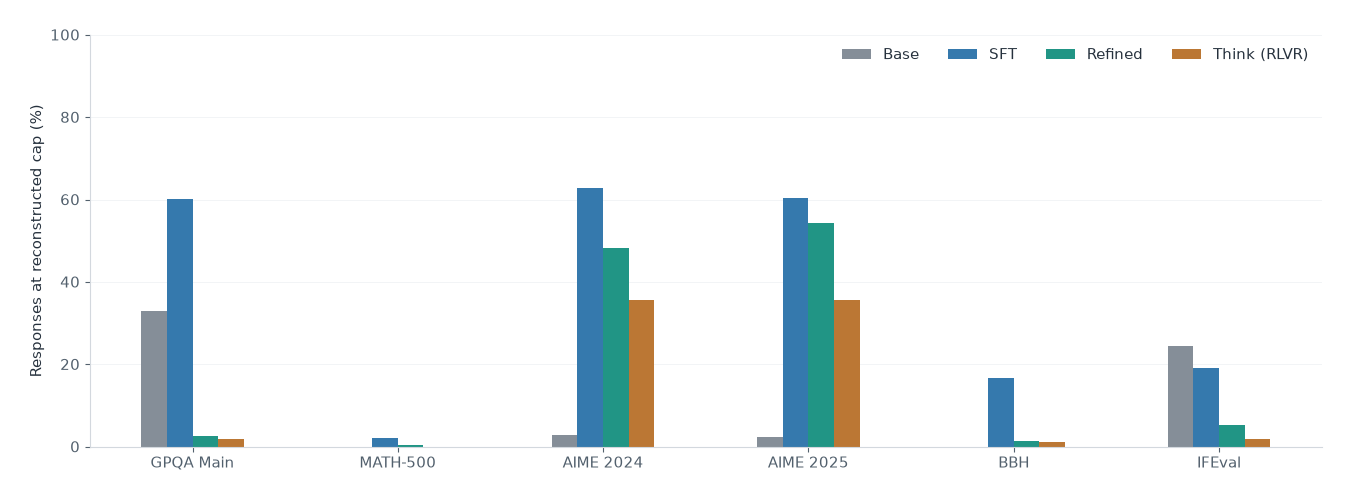

In [26]:
display(
    caps.groupby("benchmark")
    .agg(
        requested=("requested", "first"),
        model_limit=("model_limit", "first"),
        cap_min=("cap", "min"),
        cap_max=("cap", "max"),
    )
    .reindex(BENCHMARKS)
    .rename(index=TITLES)
)
signals = pd.DataFrame(
    {
        "At cap (%)": 100 * summary.at_cap,
        "Closing marker (%)": 100 * summary.closed_think,
        "Nonempty final section (%)": 100 * summary.final_section,
    }
)
display(signals.round(1))
gpqa = (
    df[df.benchmark == "gpqa"]
    .groupby("stage")
    .agg(
        actual_cap_hits=("at_cap", "mean"),
        evaluator_max_tokens_reached=("reported_cap", "mean"),
    )
    .reindex(STAGES)
)
display((100 * gpqa).round(1))

rates = (
    summary.at_cap.unstack("stage").reindex(index=BENCHMARKS, columns=STAGES) * 100
).rename(index=TITLES)
fig, ax = plt.subplots(figsize=(13, 4.5), layout="constrained")
rates.plot.bar(ax=ax, color=[COLORS[s] for s in STAGES], rot=0)
ax.set(ylabel="Responses at reconstructed cap (%)", xlabel="", ylim=(0, 100))
ax.legend(title="", ncol=4, frameon=False)
ax.grid(axis="y", alpha=0.6)
style.save(fig, FIGURES / "behavior_05_cap_hits")

## Token efficiency

Refined → Think (RLVR) on the same questions. AIME uses stored pass@1.
[Score vs. token plots](benchmarks.ipynb) are in the benchmark notebook.

In [27]:
ref = summary.xs("Refined", level="stage")
think = summary.xs("Think (RLVR)", level="stage")
comparison = pd.DataFrame(
    {
        "Refined score (%)": 100 * ref.accuracy,
        "Think score (%)": 100 * think.accuracy,
        "Score change (pp)": 100 * (think.accuracy - ref.accuracy),
        "Mean token reduction (%)": 100 * (1 - think.mean_tokens / ref.mean_tokens),
        "Median token reduction (%)": 100
        * (1 - think.median_tokens / ref.median_tokens),
        "Cap-hit change (pp)": 100 * (think.at_cap - ref.at_cap),
    }
).reindex(BENCHMARKS)
paired = questions[questions.stage == "Refined"].merge(
    questions[questions.stage == "Think (RLVR)"],
    on=["benchmark", "task", "problem"],
    suffixes=("_ref", "_think"),
    validate="one_to_one",
)
assert len(paired) == len(questions[questions.stage == "Refined"])
paired["score_change"] = paired.score_think - paired.score_ref
assert np.allclose(
    paired.groupby("benchmark").score_change.mean().reindex(BENCHMARKS),
    comparison["Score change (pp)"] / 100,
)
display(comparison.rename(index=TITLES).round(2))

,Refined score (%),Think score (%),Score change (pp),Mean token reduction (%),Median token reduction (%),Cap-hit change (pp)
benchmark,,,,,,
GPQA Main,42.63,41.74,-0.89,17.59,23.86,-0.89
MATH-500,91.00,91.00,0.00,16.17,19.38,-0.40
AIME 2024,45.83,45.31,-0.52,9.24,16.72,-12.81
AIME 2025,33.33,33.33,-0.00,8.48,14.13,-18.65
BBH,67.61,69.19,1.58,21.74,21.81,-0.32
IFEval,72.64,72.64,0.00,43.87,19.02,-3.33


## Accuracy by length

AIME bins problems by mean response length and uses stored pass@1. Other suites use single responses. Marker size shows count.
Scores are conditional on length; difficulty, cap hits and BBH task mix can affect them.

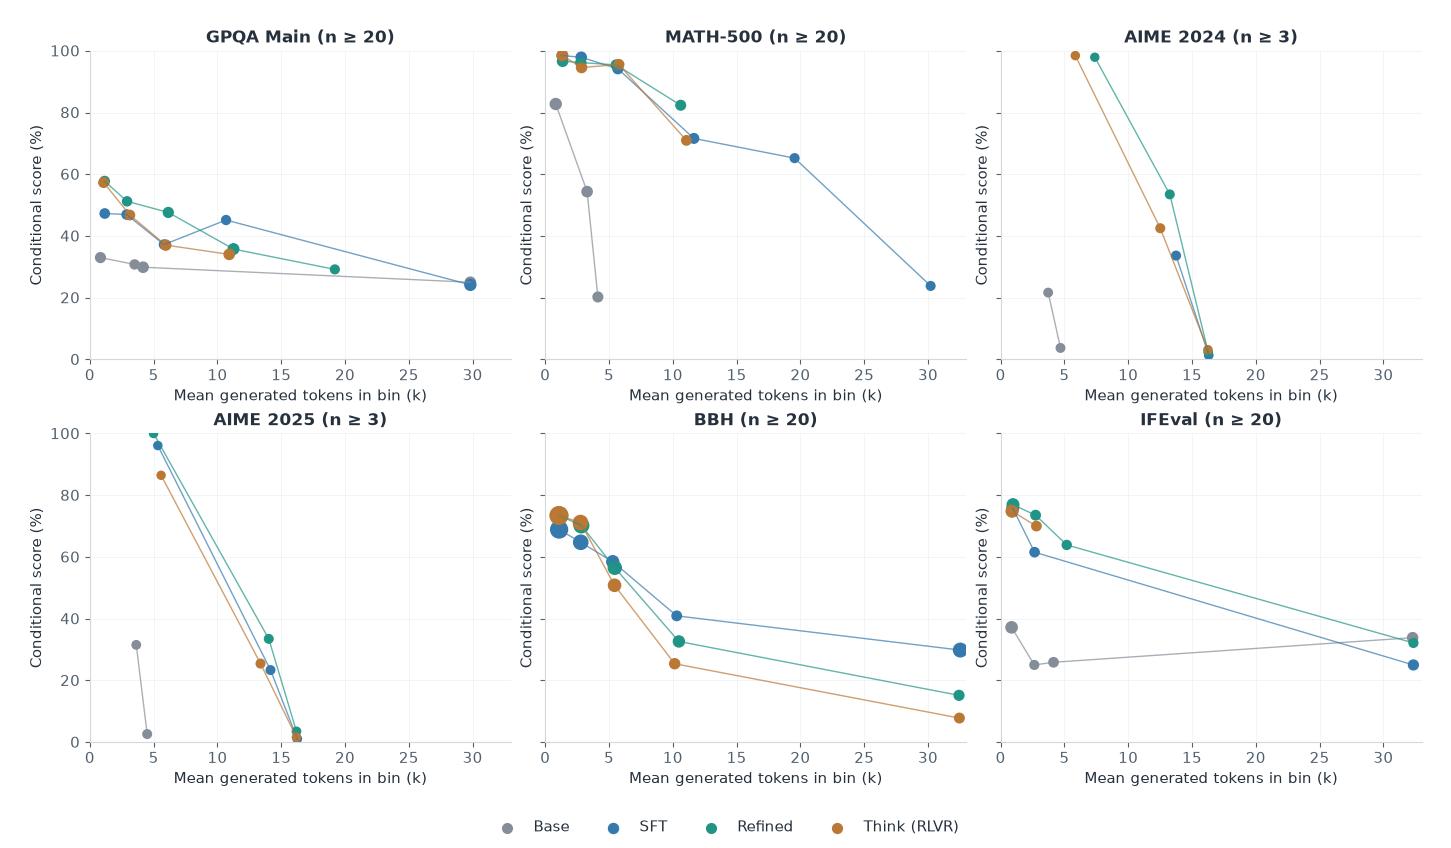

In [28]:
bins = [0, 2000, 4000, 8000, 16000, 24000, 33000]
questions["length_bin"] = pd.cut(questions.tokens, bins=bins, right=False)
binned = (
    questions.groupby(["benchmark", "stage", "length_bin"], observed=True)
    .agg(
        n=("score", "size"),
        score=("score", "mean"),
        mean_tokens=("tokens", "mean"),
    )
    .reset_index()
)
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True, layout="constrained")
for ax, benchmark in zip(axes.flat, BENCHMARKS):
    minimum = 3 if benchmark.startswith("aime") else 20
    for stage in STAGES:
        g = binned[
            (binned.benchmark == benchmark)
            & (binned.stage == stage)
            & (binned.n >= minimum)
        ]
        ax.plot(
            g.mean_tokens / 1000, 100 * g.score, color=COLORS[stage], alpha=0.7, lw=1
        )
        ax.scatter(
            g.mean_tokens / 1000,
            100 * g.score,
            s=30 + 2 * np.sqrt(g.n),
            color=COLORS[stage],
            label=stage,
        )
    ax.set(
        title=f"{TITLES[benchmark]} (n ≥ {minimum})",
        xlabel="Mean generated tokens in bin (k)",
        ylabel="Conditional score (%)",
        ylim=(0, 100),
        xlim=(0, 33),
    )
    ax.grid(alpha=0.6)
fig.legend(
    *axes.flat[0].get_legend_handles_labels(),
    loc="outside lower center",
    ncol=4,
    frameon=False,
)
style.save(fig, FIGURES / "behavior_07_accuracy_length")

## Answer outcomes

Answer signals: a nonempty box on math/AIME, the preferred format on GPQA, a nonempty extracted answer on BBH, and nonempty graded text on IFEval.
AIME has no saved per-response grades, so it is excluded from the outcome chart. IFEval uses prompt-level loose accuracy.

responses  Answer signal (%)  Overall score (%)  \
benchmark stage                                                           
gpqa      Base                448               31.9               28.8   
          SFT                 448               35.7               32.4   
          Refined             448               66.3               42.6   
          Think (RLVR)        448               71.2               41.7   
math500   Base                500               73.2               63.0   
          SFT                 500               98.2               88.4   
          Refined             500               99.6               91.0   
          Think (RLVR)        500               99.8               91.0   
aime-2024 Base                960               15.1               12.1   
          SFT                 960               39.0               30.2   
          Refined             960               55.8               45.8   
          Think (RLVR)        960               69.2               45.3   
aime-2025 Base                960               18.9               14.2   
          SFT                 960               42.3               26.4   
          Refined             960               49.8               33.3   
          Think (RLVR)        960               69.4               33.3   
bbh       SFT                6511               89.7               60.3   
          Refined            6511               92.0               67.6   
          Think (RLVR)       6511               93.0               69.2   
ifeval    Base                541               93.0               34.6   
          SFT                 541              100.0               63.8   
          Refined             541              100.0               72.6   
          Think (RLVR)        541              100.0               72.6   

                       Accuracy | signal (%)  Correct without signal (%)  \
benchmark stage                                                            
gpqa      Base                     32.867133                        18.3   
          SFT                         43.125                        17.0   
          Refined                  47.474747                        11.2   
          Think (RLVR)             43.573668                        10.7   
math500   Base                     85.519126                         0.4   
          SFT                      90.020367                         0.0   
          Refined                  91.365462                         0.0   
          Think (RLVR)             91.182365                         0.0   
aime-2024 Base                           NaN                         NaN   
          SFT                            NaN                         NaN   
          Refined                        NaN                         NaN   
          Think (RLVR)                   NaN                         NaN   
aime-2025 Base                           NaN                         NaN   
          SFT                            NaN                         NaN   
          Refined                        NaN                         NaN   
          Think (RLVR)                   NaN                         NaN   
bbh       SFT                      67.242855                         0.0   
          Refined                  73.464619                         0.0   
          Think (RLVR)             74.376754                         0.0   
ifeval    Base                     37.176938                         0.0   
          SFT                      63.770795                         0.0   
          Refined                  72.643253                         0.0   
          Think (RLVR)             72.643253                         0.0   

                       Box after closing marker (%)  
benchmark stage                                      
gpqa      Base                                  NaN  
          SFT                                   NaN  
          Refined              

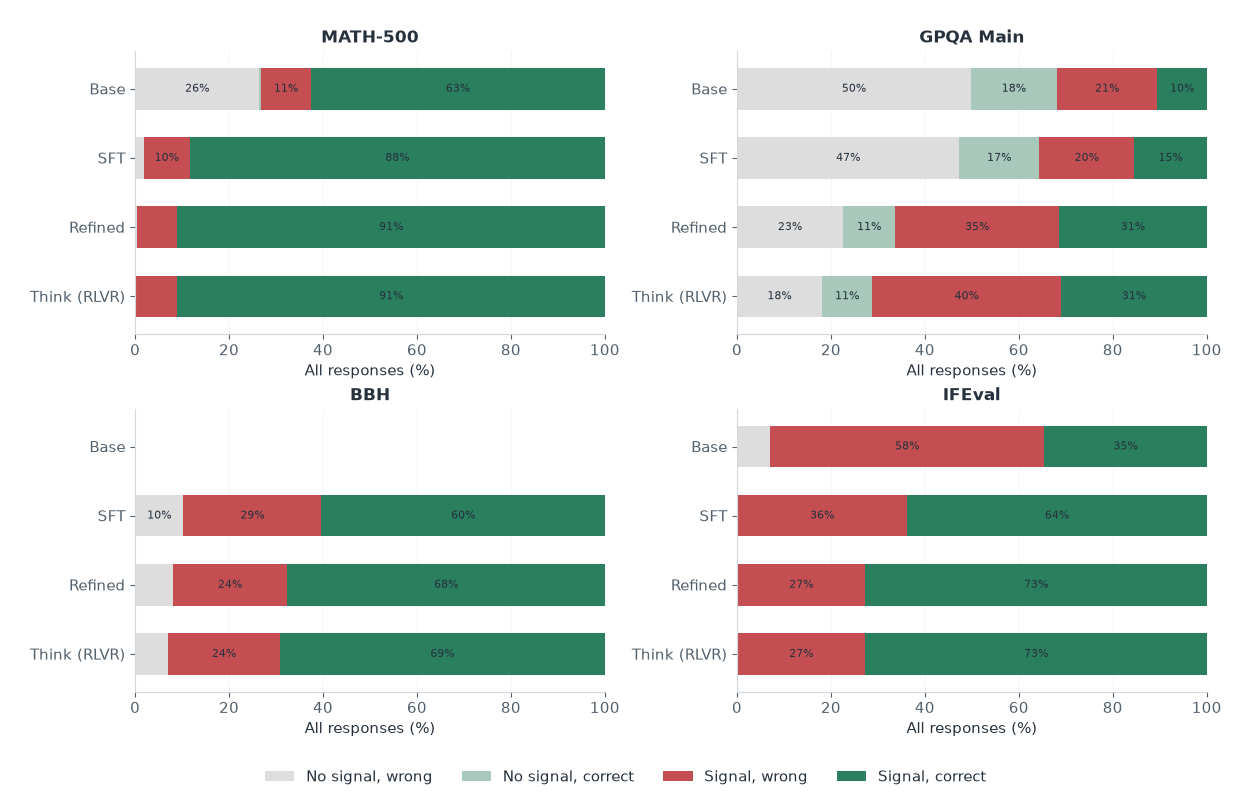

In [29]:
answer_summary = summary[["responses", "answered", "accuracy"]].copy()
answer_summary["answered"] *= 100
answer_summary["accuracy"] *= 100
answer_summary = answer_summary.rename(
    columns={"answered": "Answer signal (%)", "accuracy": "Overall score (%)"}
)
known = df[df.correct.notna()].copy()
conditional = known[known.answered].groupby(["benchmark", "stage"]).correct.mean() * 100
answer_summary["Accuracy | signal (%)"] = conditional
answer_summary["Correct without signal (%)"] = (
    known.assign(value=lambda x: x.correct.astype(bool) & ~x.answered)
    .groupby(["benchmark", "stage"])
    .value.mean()
    * 100
)
answer_summary["Box after closing marker (%)"] = (
    100 * df.groupby(["benchmark", "stage"]).final_box.mean()
)
display(answer_summary.round(1))

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
outcome_benchmarks = ["math500", "gpqa", "bbh", "ifeval"]
outcome_colors = ["#dddddd", "#a7c8bb", "#c44e52", "#2a7f5f"]
for ax, benchmark in zip(axes.flat, outcome_benchmarks):
    g = known[known.benchmark == benchmark].copy()
    correct = g.correct.astype(bool)
    g["outcome"] = np.select(
        [~g.answered & ~correct, ~g.answered & correct, g.answered & ~correct],
        [0, 1, 2],
        default=3,
    )
    counts = pd.crosstab(g.stage, g.outcome).reindex(columns=range(4), fill_value=0)
    outcomes = counts.div(counts.sum(axis=1), axis=0).reindex(STAGES) * 100
    outcomes.columns = [
        "No signal, wrong",
        "No signal, correct",
        "Signal, wrong",
        "Signal, correct",
    ]
    outcomes.plot.barh(
        stacked=True, ax=ax, color=outcome_colors, width=0.6, legend=False
    )
    ax.invert_yaxis()
    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[
                f"{bar.get_width():.0f}%" if bar.get_width() >= 9 else ""
                for bar in container
            ],
            label_type="center",
            fontsize=8,
        )
    ax.set(
        title=TITLES[benchmark], xlabel="All responses (%)", ylabel="", xlim=(0, 100)
    )
    ax.grid(axis="x", alpha=0.5)
fig.legend(
    *axes.flat[0].get_legend_handles_labels(),
    loc="outside lower center",
    ncol=4,
    frameon=False,
)
style.save(fig, FIGURES / "behavior_08_answer_outcomes")

## Repetition

Share of overlapping ten-word spans seen earlier in the response.

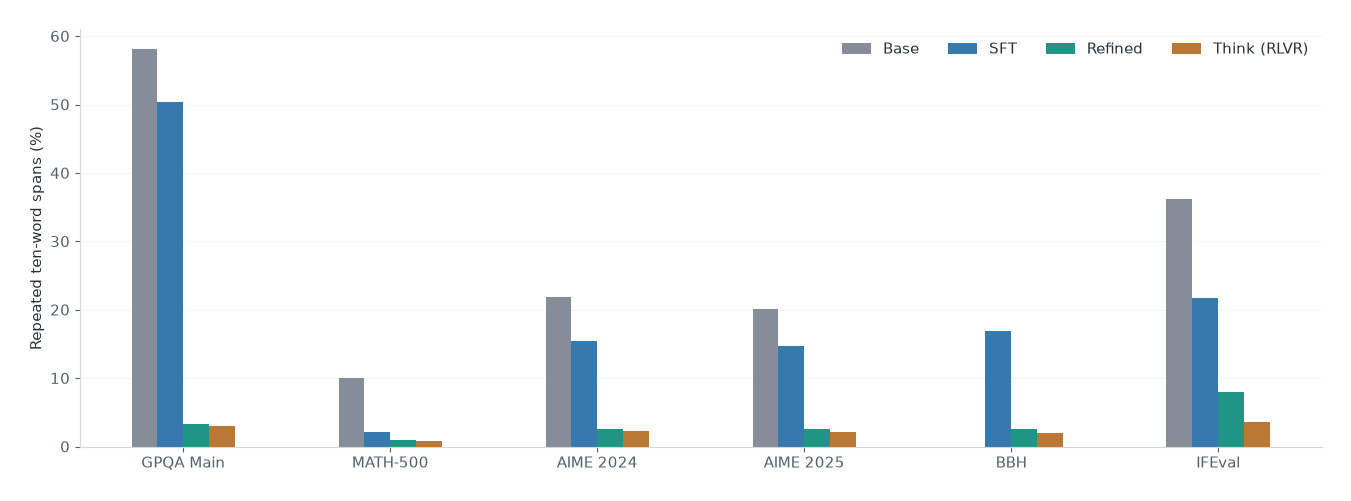

In [30]:
repetition = (100 * summary.repetition.unstack("stage")).reindex(
    index=BENCHMARKS, columns=STAGES
)
fig, ax = plt.subplots(figsize=(13, 4.5), layout="constrained")
repetition.rename(index=TITLES).plot.bar(
    ax=ax, color=[COLORS[s] for s in STAGES], rot=0
)
ax.set(ylabel="Repeated ten-word spans (%)", xlabel="")
ax.legend(title="", ncol=4, frameon=False)
ax.grid(axis="y", alpha=0.6)
style.save(fig, FIGURES / "behavior_09_repetition")